# Descente de gradient à pas fixe

On minimise la fonction de Rosenbrock avec

x_{k+1} = x_k - alpha * grad f(x_k)

On utilisera la même fonction et le même point de départ dans les trois notebooks pour pouvoir comparer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# fonction de Rosenbrock (meme fonction dans les trois notebooks)
def f(x):
    return (1 - x[0])**2 + 100*(x[1] - x[0]**2)**2

def grad_f(x):
    return np.array([
        -2*(1 - x[0]) - 400*x[0]*(x[1] - x[0]**2),
        200*(x[1] - x[0]**2)
    ])

x0 = np.array([-1.2, 1.0])   # point de depart
x_etoile = np.array([1.0, 1.0])  # minimum connu, f(x*) = 0
tol = 1e-6
max_iter = 50000

In [2]:
def gradient_pas_fixe(x0, alpha, tol, max_iter):
    x = x0.copy()
    hist_x = [x.copy()]
    hist_f = [f(x)]
    for k in range(max_iter):
        g = grad_f(x)
        if np.linalg.norm(g) < tol:
            break
        x = x - alpha * g
        hist_x.append(x.copy())
        hist_f.append(f(x))
    return x, k, np.array(hist_x), np.array(hist_f)

In [3]:
alpha = 1e-3
x_fin, nb_iter, hist_x, hist_f = gradient_pas_fixe(x0, alpha, tol, max_iter)

print("alpha :", alpha)
print("iterations :", nb_iter)
print("x final :", x_fin)
print("f(x final) :", f(x_fin))
print("norme du gradient :", np.linalg.norm(grad_f(x_fin)))

alpha : 0.001
iterations : 32076
x final : [0.99999888 0.99999776]
f(x final) : 1.2517236788075983e-12
norme du gradient : 9.998902160830393e-07


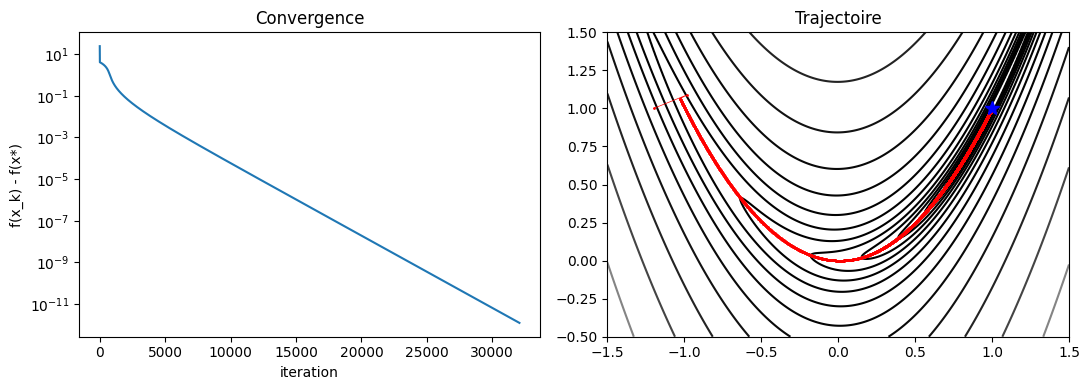

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].semilogy(np.maximum(hist_f, 1e-16))
ax[0].set_xlabel("iteration")
ax[0].set_ylabel("f(x_k) - f(x*)")
ax[0].set_title("Convergence")

X, Y = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-0.5, 1.5, 300))
Z = (1 - X)**2 + 100*(Y - X**2)**2
ax[1].contour(X, Y, Z, levels=np.logspace(-1, 3, 15), cmap="gray")
ax[1].plot(hist_x[:, 0], hist_x[:, 1], "r.-", lw=0.5, ms=2)
ax[1].plot(*x_etoile, "b*", ms=10)
ax[1].set_title("Trajectoire")

plt.tight_layout()
plt.show()

On teste aussi d'autres valeurs de alpha pour voir l'influence du pas.

In [5]:
for a in [1e-4, 5e-4, 1e-3, 2e-3, 3e-3]:
    x_fin, nb_iter, _, _ = gradient_pas_fixe(x0, a, tol, max_iter)
    print(a, nb_iter, f(x_fin))

0.0001 49999 0.0037817660161678455


0.0005 49999 3.5877101037913916e-10
0.001 32076 1.2517236788075983e-12


0.002 49999 0.0012495449510668212


0.003 49999 0.32659494275675094
